# Month 1 — Week 4: Data Visualisation with Matplotlib and Seaborn
**Skybrisk Internship | Md Tarique Atique**

Covers: Matplotlib basics (line, bar, scatter, histogram, pie, subplots, styling) and
Seaborn advanced plots (histplot/kde, boxplot, violin, heatmap, pairplot, regplot, countplot).
Client project: a multi-panel dashboard of feature relationships, exported as PNG.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

%matplotlib inline
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({"figure.figsize": (8, 4.5), "figure.dpi": 110,
                     "axes.titlesize": 12, "axes.titleweight": "bold"})
os.makedirs("plots", exist_ok=True)
print("Seaborn", sns.__version__)

Seaborn 0.13.2


## 1. Load data (Week 3 output if available, else the raw CSV)

In [2]:
if os.path.exists("week3_clean_dataset.csv"):
    df = pd.read_csv("week3_clean_dataset.csv", parse_dates=["date"])
else:
    df = pd.read_csv("data/weather_energy.csv", parse_dates=["date"])
    df = df.drop_duplicates(subset=[c for c in df.columns if c != "record_id"])
    df = df.dropna(subset=["temperature_c"])
    for col in ["humidity", "wind_kmph", "energy_units"]:
        df[col] = df.groupby("city")[col].transform(lambda s: s.fillna(s.median()))
    df["temp_f"] = (df.temperature_c * 9 / 5 + 32).round(1)
    df["month"] = df.date.dt.month_name().str[:3]
    df["comfort"] = pd.cut(df.temperature_c, [-np.inf, 15, 25, 33, np.inf],
                           labels=["Cold", "Pleasant", "Warm", "Hot"])

num_cols = ["temperature_c", "humidity", "wind_kmph", "energy_units"]
print(df.shape)
df.head()

(182, 11)


,record_id,city,date,temperature_c,humidity,wind_kmph,energy_units,temp_f,month,comfort,energy_per_degree
0,139,Delhi,2025-05-19,14.1,33.5,2.0,283.0,57.4,May,Cold,20.07
1,66,Delhi,2025-03-07,22.1,39.6,6.8,329.2,71.8,Mar,Pleasant,14.90
2,96,Delhi,2025-04-06,35.8,87.1,15.4,423.5,96.4,Apr,Hot,11.83
3,64,Kolkata,2025-03-05,22.6,67.2,8.0,348.6,72.7,Mar,Pleasant,15.42
4,47,Mumbai,2025-02-16,22.1,79.7,2.3,354.4,71.8,Feb,Pleasant,16.04


## 2. Matplotlib — line plot

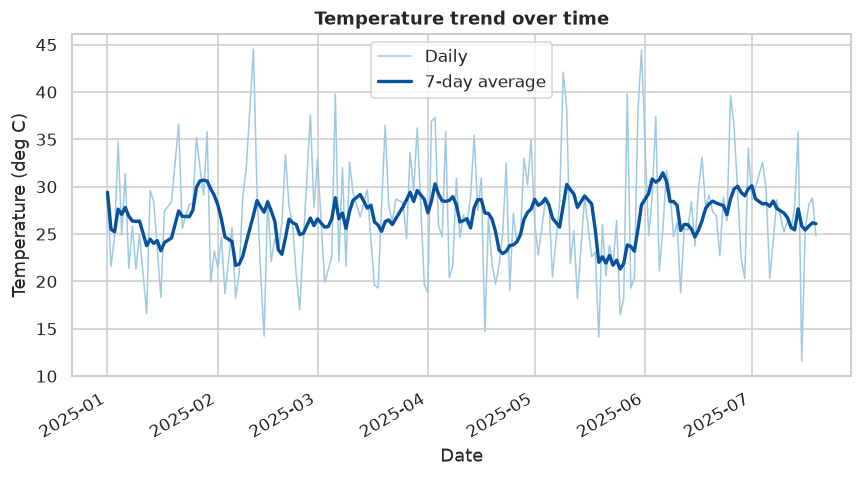

In [3]:
daily = df.sort_values("date").set_index("date")["temperature_c"]
rolling = daily.rolling(7, min_periods=1).mean()

fig, ax = plt.subplots()
ax.plot(daily.index, daily.values, color="#9ecae1", lw=1, label="Daily")
ax.plot(rolling.index, rolling.values, color="#08519c", lw=2.2, label="7-day average")
ax.set_title("Temperature trend over time")
ax.set_xlabel("Date"); ax.set_ylabel("Temperature (deg C)")
ax.legend(); fig.autofmt_xdate(); plt.tight_layout()
plt.savefig("plots/01_line_trend.png", bbox_inches="tight"); plt.show()

## 3. Matplotlib — bar and horizontal bar

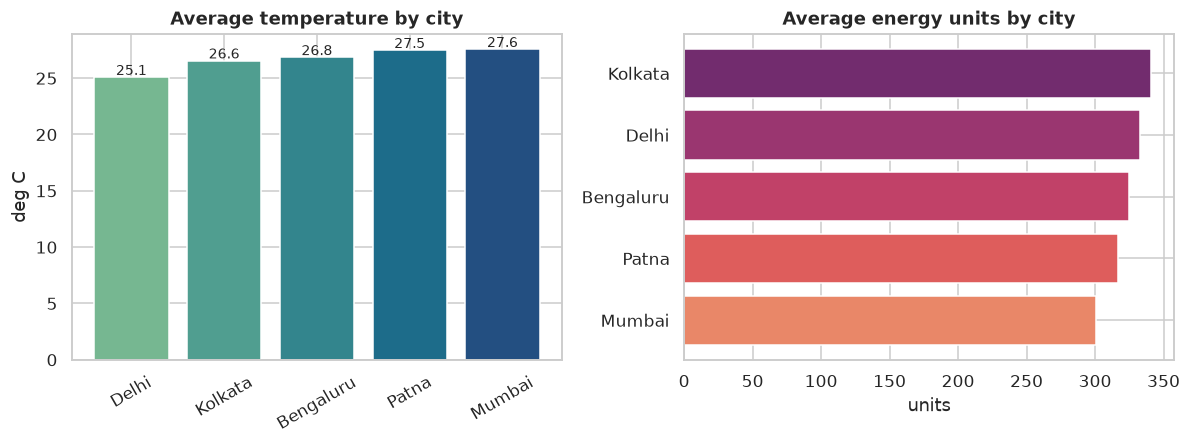

In [4]:
avg = df.groupby("city")["temperature_c"].mean().sort_values()

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
bars = axes[0].bar(avg.index, avg.values, color=sns.color_palette("crest", len(avg)))
axes[0].set_title("Average temperature by city")
axes[0].set_ylabel("deg C"); axes[0].tick_params(axis="x", rotation=30)
for b, v in zip(bars, avg.values):
    axes[0].text(b.get_x() + b.get_width() / 2, v + 0.2, f"{v:.1f}",
                 ha="center", fontsize=9)

energy = df.groupby("city")["energy_units"].mean().sort_values()
axes[1].barh(energy.index, energy.values, color=sns.color_palette("flare", len(energy)))
axes[1].set_title("Average energy units by city"); axes[1].set_xlabel("units")
plt.tight_layout(); plt.savefig("plots/02_bars.png", bbox_inches="tight"); plt.show()

## 4. Matplotlib — scatter, histogram and pie

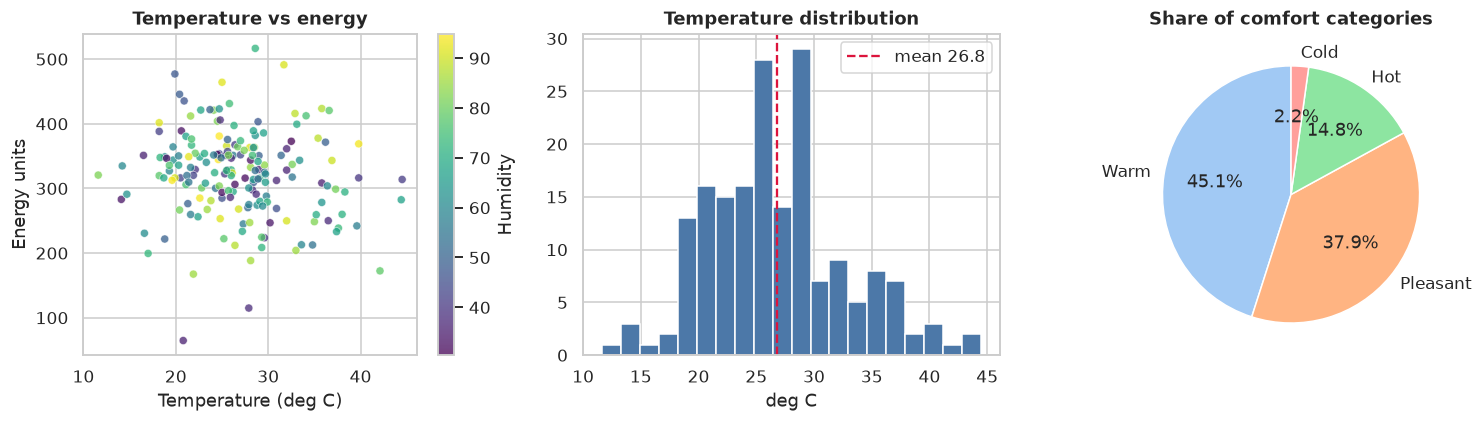

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

sc = axes[0].scatter(df.temperature_c, df.energy_units, c=df.humidity,
                     cmap="viridis", alpha=0.75, s=28, edgecolor="white", lw=0.4)
axes[0].set_title("Temperature vs energy")
axes[0].set_xlabel("Temperature (deg C)"); axes[0].set_ylabel("Energy units")
fig.colorbar(sc, ax=axes[0], label="Humidity")

axes[1].hist(df.temperature_c, bins=20, color="#4c78a8", edgecolor="white")
axes[1].axvline(df.temperature_c.mean(), color="crimson", ls="--",
                label=f"mean {df.temperature_c.mean():.1f}")
axes[1].set_title("Temperature distribution"); axes[1].set_xlabel("deg C"); axes[1].legend()

counts = df.comfort.value_counts()
axes[2].pie(counts.values, labels=counts.index, autopct="%1.1f%%",
            colors=sns.color_palette("pastel"), startangle=90,
            wedgeprops={"edgecolor": "white"})
axes[2].set_title("Share of comfort categories")
plt.tight_layout(); plt.savefig("plots/03_scatter_hist_pie.png", bbox_inches="tight"); plt.show()

## 5. Seaborn — distributions (histplot, kdeplot, boxplot, violinplot)

/tmp/ipykernel_663/2742669480.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="city", y="temperature_c", ax=axes[1, 0], palette="crest")
/tmp/ipykernel_663/2742669480.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df, x="city", y="energy_units", ax=axes[1, 1], palette="flare", inner="quartile")


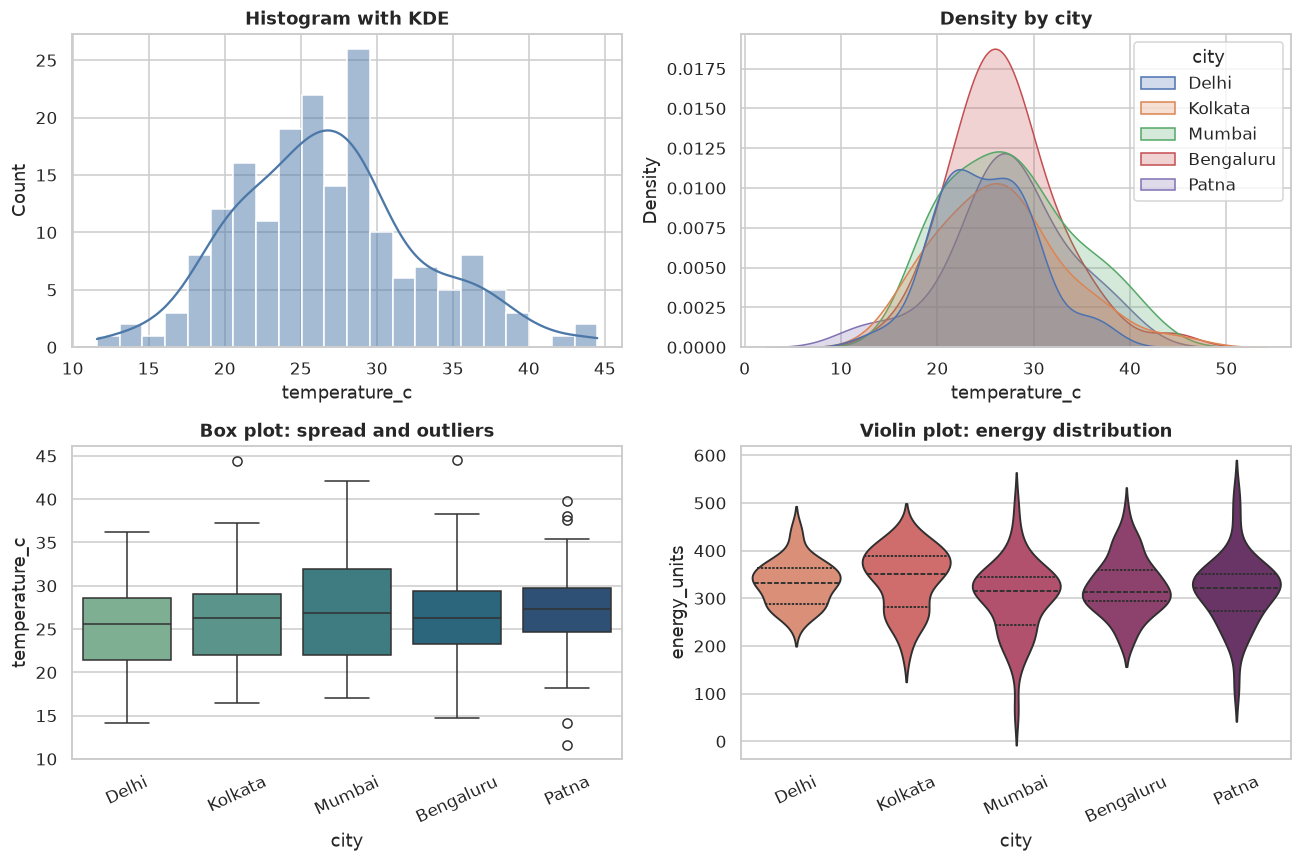

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

sns.histplot(data=df, x="temperature_c", kde=True, bins=22, ax=axes[0, 0], color="#4c78a8")
axes[0, 0].set_title("Histogram with KDE")

sns.kdeplot(data=df, x="temperature_c", hue="city", fill=True, alpha=0.25, ax=axes[0, 1])
axes[0, 1].set_title("Density by city")

sns.boxplot(data=df, x="city", y="temperature_c", ax=axes[1, 0], palette="crest")
axes[1, 0].set_title("Box plot: spread and outliers")
axes[1, 0].tick_params(axis="x", rotation=25)

sns.violinplot(data=df, x="city", y="energy_units", ax=axes[1, 1], palette="flare", inner="quartile")
axes[1, 1].set_title("Violin plot: energy distribution")
axes[1, 1].tick_params(axis="x", rotation=25)

plt.tight_layout(); plt.savefig("plots/04_seaborn_distributions.png", bbox_inches="tight"); plt.show()

## 6. Seaborn — correlation heatmap

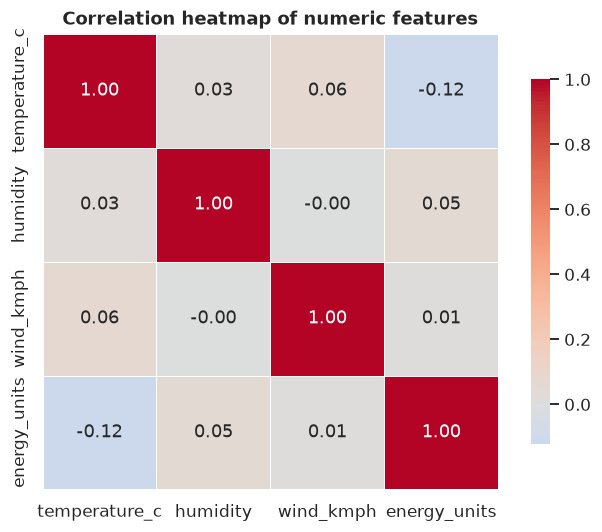

               temperature_c  humidity  wind_kmph  energy_units
temperature_c           1.00      0.03       0.06         -0.12
humidity                0.03      1.00      -0.00          0.05
wind_kmph               0.06     -0.00       1.00          0.01
energy_units           -0.12      0.05       0.01          1.00


In [7]:
corr = df[num_cols].corr(numeric_only=True)
plt.figure(figsize=(6.5, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            linewidths=.5, square=True, cbar_kws={"shrink": .8})
plt.title("Correlation heatmap of numeric features")
plt.tight_layout(); plt.savefig("plots/05_heatmap.png", bbox_inches="tight"); plt.show()
print(corr.round(2))

## 7. Seaborn — pairplot, regression and categorical counts

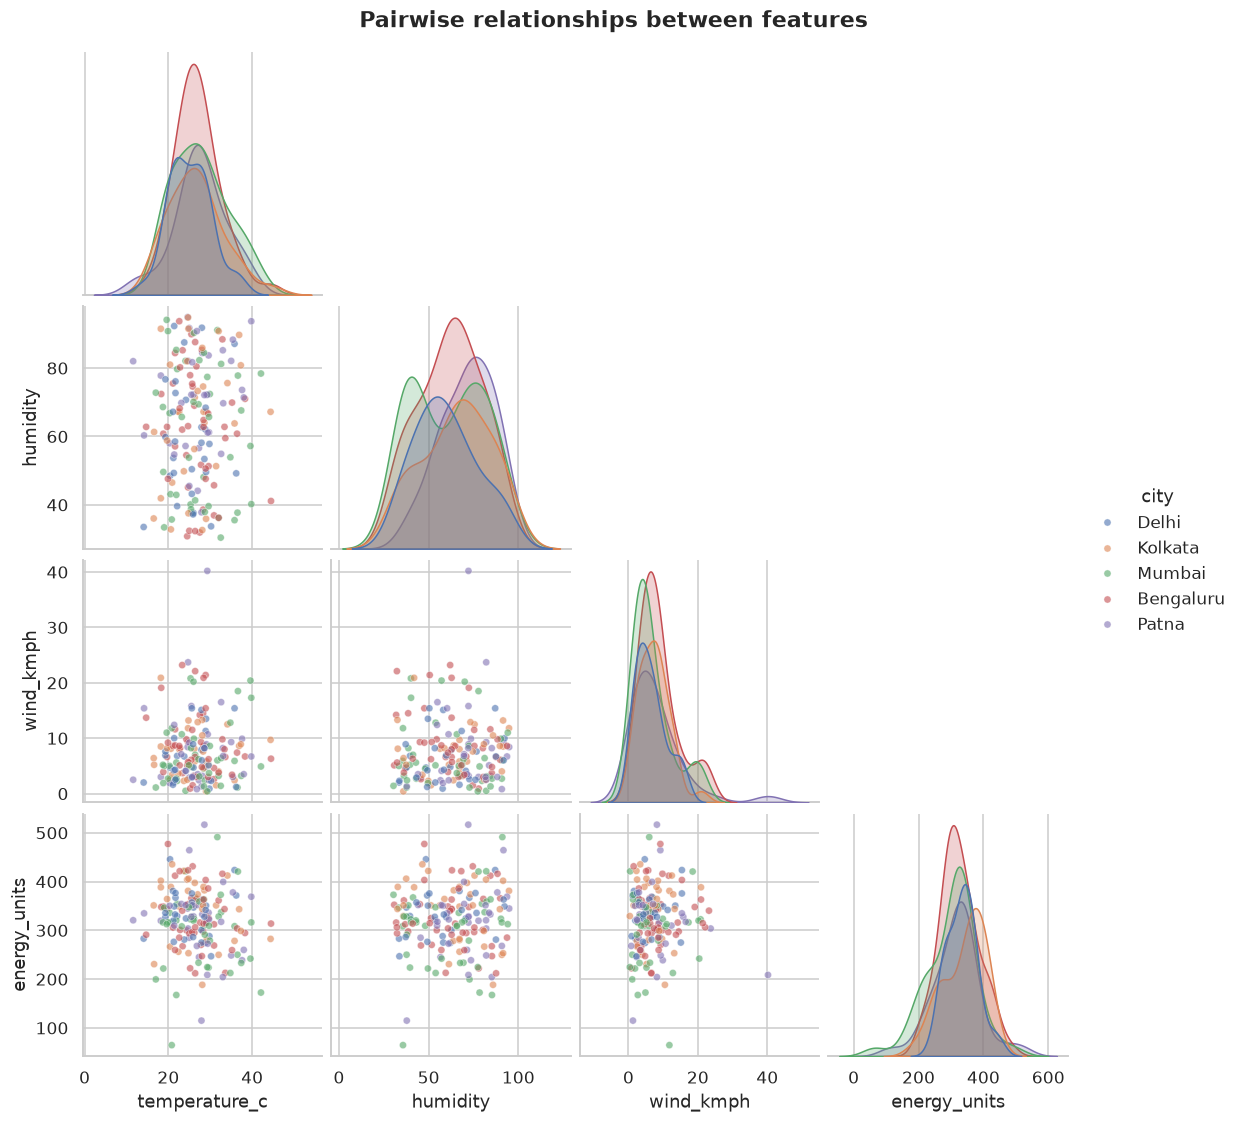

In [8]:
pp = sns.pairplot(df[num_cols + ["city"]], hue="city", diag_kind="kde",
                  corner=True, plot_kws={"alpha": .6, "s": 22})
pp.figure.suptitle("Pairwise relationships between features", y=1.02, fontweight="bold")
pp.savefig("plots/06_pairplot.png", bbox_inches="tight"); plt.show()

/tmp/ipykernel_663/2328073442.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x="city", y="humidity", ax=axes[2], errorbar="sd", palette="mako")


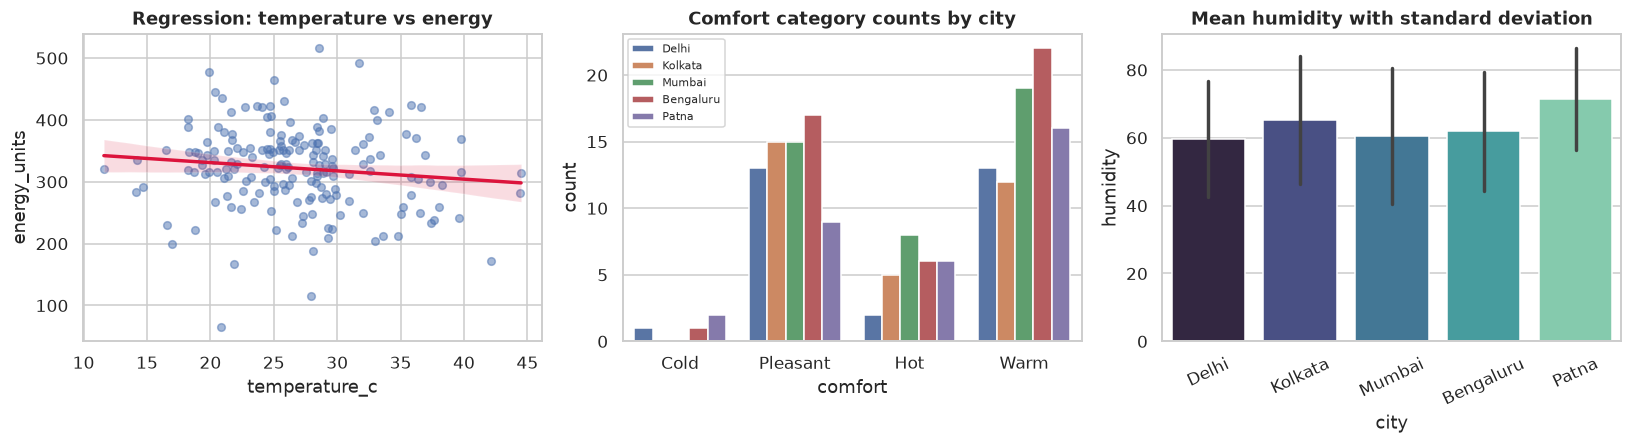

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))

sns.regplot(data=df, x="temperature_c", y="energy_units", ax=axes[0],
            scatter_kws={"alpha": .5, "s": 25}, line_kws={"color": "crimson"})
axes[0].set_title("Regression: temperature vs energy")

sns.countplot(data=df, x="comfort", hue="city", ax=axes[1])
axes[1].set_title("Comfort category counts by city")
axes[1].legend(fontsize=7, title=None)

sns.barplot(data=df, x="city", y="humidity", ax=axes[2], errorbar="sd", palette="mako")
axes[2].set_title("Mean humidity with standard deviation")
axes[2].tick_params(axis="x", rotation=25)

plt.tight_layout(); plt.savefig("plots/07_regression_categorical.png", bbox_inches="tight"); plt.show()

## Client Project — feature-relationship dashboard

One figure, six panels, built with `GridSpec`: KPI strip, trend, distribution, scatter with
regression line, correlation heatmap and a city comparison.

/tmp/ipykernel_663/4197445328.py:59: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="city", y="temperature_c", palette="crest", ax=ax5)


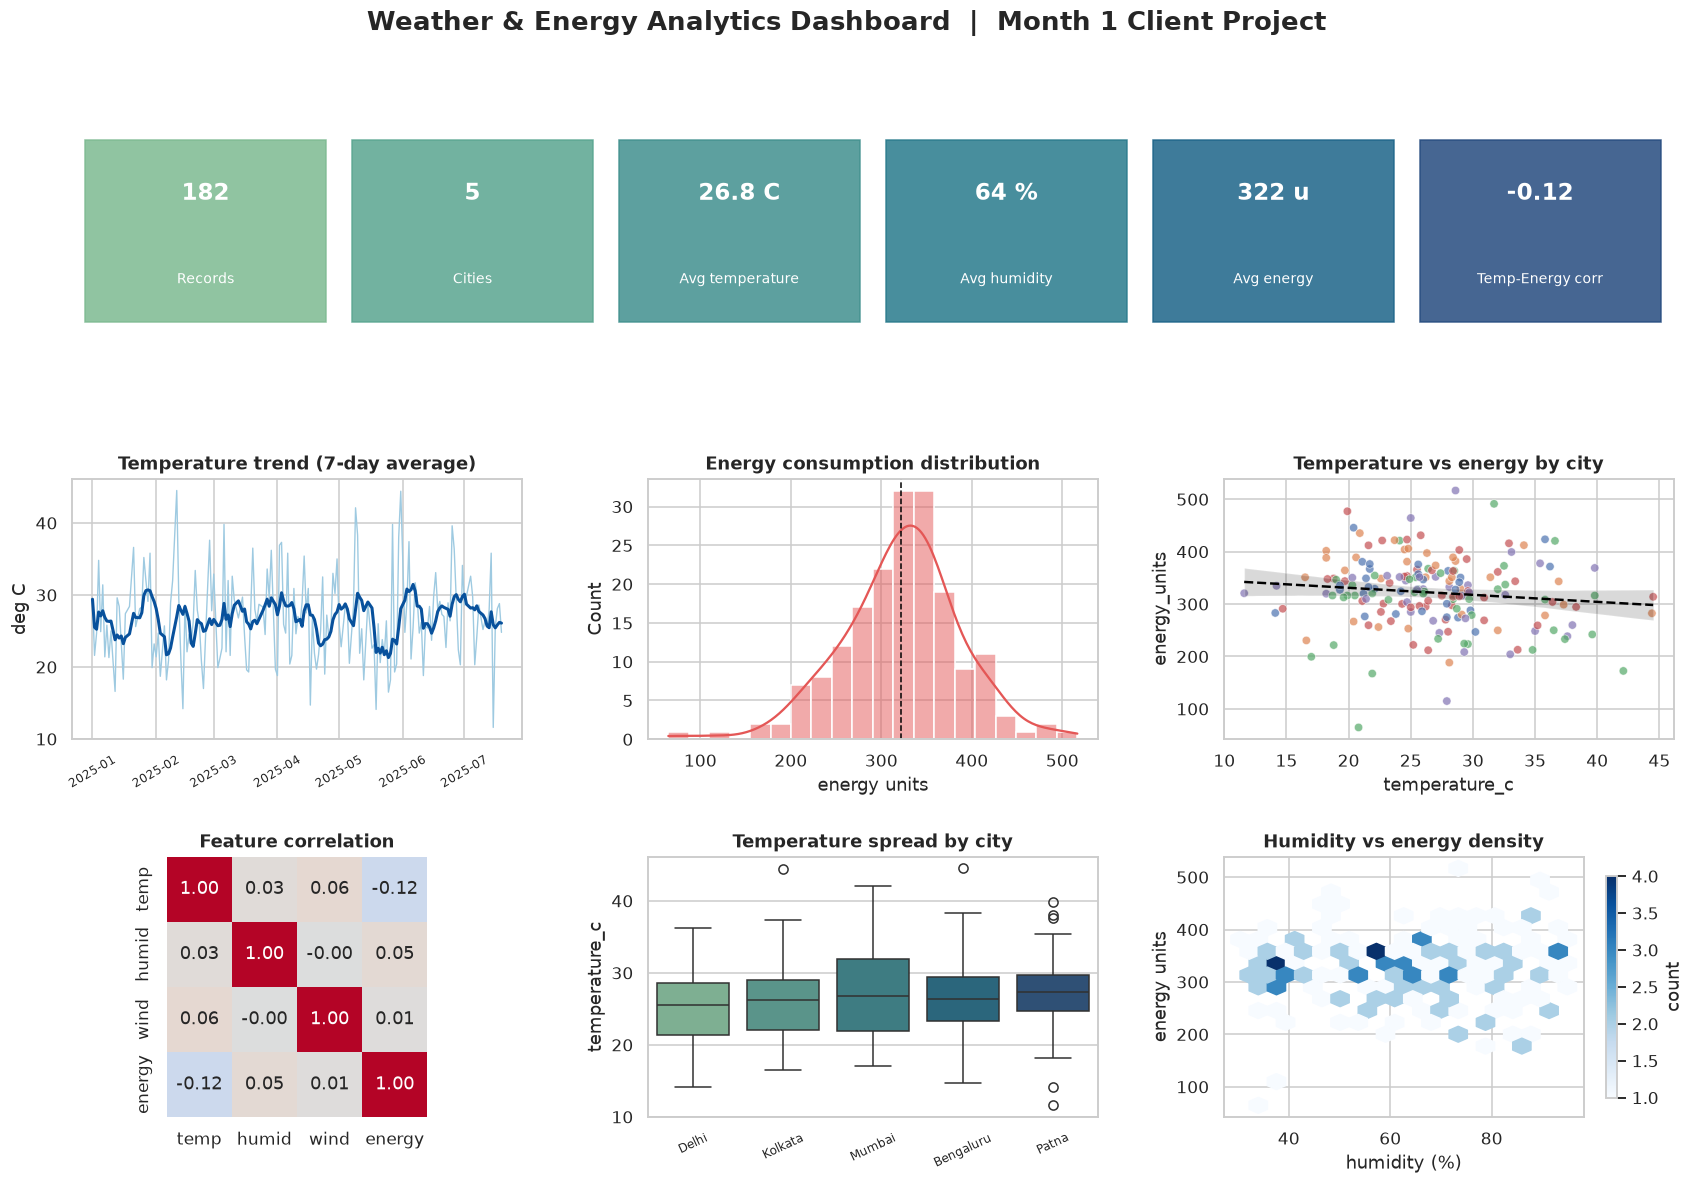

Saved -> plots/08_dashboard.png


In [10]:
from matplotlib.gridspec import GridSpec

fig = plt.figure(figsize=(16, 11))
fig.suptitle("Weather & Energy Analytics Dashboard  |  Month 1 Client Project",
             fontsize=17, fontweight="bold", y=0.975)
gs = GridSpec(3, 3, figure=fig, hspace=0.45, wspace=0.28,
              top=0.90, bottom=0.06, left=0.06, right=0.97)

# --- panel 1: KPI strip ---
ax_kpi = fig.add_subplot(gs[0, :]); ax_kpi.axis("off")
kpis = [("Records", f"{len(df):,}"),
        ("Cities", f"{df.city.nunique()}"),
        ("Avg temperature", f"{df.temperature_c.mean():.1f} C"),
        ("Avg humidity", f"{df.humidity.mean():.0f} %"),
        ("Avg energy", f"{df.energy_units.mean():.0f} u"),
        ("Temp-Energy corr", f"{df.temperature_c.corr(df.energy_units):+.2f}")]
colors = sns.color_palette("crest", len(kpis))
for i, ((label, value), col) in enumerate(zip(kpis, colors)):
    x = i / len(kpis) + 0.008
    ax_kpi.add_patch(plt.Rectangle((x, 0.15), 1 / len(kpis) - 0.016, 0.7,
                                   color=col, alpha=.85, transform=ax_kpi.transAxes))
    ax_kpi.text(x + (1 / len(kpis) - 0.016) / 2, 0.62, value, ha="center",
                fontsize=15, fontweight="bold", color="white", transform=ax_kpi.transAxes)
    ax_kpi.text(x + (1 / len(kpis) - 0.016) / 2, 0.30, label, ha="center",
                fontsize=9, color="white", transform=ax_kpi.transAxes)

# --- panel 2: trend ---
ax1 = fig.add_subplot(gs[1, 0])
d = df.sort_values("date")
ax1.plot(d.date, d.temperature_c, color="#9ecae1", lw=.9)
ax1.plot(d.date, d.temperature_c.rolling(7, min_periods=1).mean(), color="#08519c", lw=2)
ax1.set_title("Temperature trend (7-day average)"); ax1.set_ylabel("deg C")
ax1.tick_params(axis="x", rotation=30, labelsize=8)

# --- panel 3: distribution ---
ax2 = fig.add_subplot(gs[1, 1])
sns.histplot(data=df, x="energy_units", kde=True, bins=20, color="#e45756", ax=ax2)
ax2.axvline(df.energy_units.mean(), ls="--", color="black", lw=1)
ax2.set_title("Energy consumption distribution"); ax2.set_xlabel("energy units")

# --- panel 4: scatter + regression ---
ax3 = fig.add_subplot(gs[1, 2])
sns.scatterplot(data=df, x="temperature_c", y="energy_units", hue="city",
                alpha=.7, s=30, ax=ax3, legend=False)
sns.regplot(data=df, x="temperature_c", y="energy_units", scatter=False,
            color="black", ax=ax3, line_kws={"lw": 1.6, "ls": "--"})
ax3.set_title("Temperature vs energy by city")

# --- panel 5: heatmap ---
ax4 = fig.add_subplot(gs[2, 0])
sns.heatmap(df[num_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0,
            cbar=False, square=True, ax=ax4,
            xticklabels=["temp", "humid", "wind", "energy"],
            yticklabels=["temp", "humid", "wind", "energy"])
ax4.set_title("Feature correlation")

# --- panel 6: city boxplot ---
ax5 = fig.add_subplot(gs[2, 1])
sns.boxplot(data=df, x="city", y="temperature_c", palette="crest", ax=ax5)
ax5.set_title("Temperature spread by city"); ax5.set_xlabel("")
ax5.tick_params(axis="x", rotation=25, labelsize=8)

# --- panel 7: humidity vs energy hexbin-style density ---
ax6 = fig.add_subplot(gs[2, 2])
hb = ax6.hexbin(df.humidity, df.energy_units, gridsize=18, cmap="Blues", mincnt=1)
ax6.set_title("Humidity vs energy density")
ax6.set_xlabel("humidity (%)"); ax6.set_ylabel("energy units")
fig.colorbar(hb, ax=ax6, shrink=.85, label="count")

plt.savefig("plots/08_dashboard.png", dpi=140, bbox_inches="tight")
plt.show()
print("Saved -> plots/08_dashboard.png")

In [11]:
# Numeric findings that back up the dashboard
print("Correlation with energy_units:")
print(df[num_cols].corr()["energy_units"].drop("energy_units").round(3).to_string())
print("\nCity ranking by average temperature:")
print(df.groupby("city")["temperature_c"].mean().round(2)
        .sort_values(ascending=False).to_string())
print("\nComfort category share (%):")
print((df.comfort.value_counts(normalize=True) * 100).round(1).to_string())

Correlation with energy_units:
temperature_c   -0.122
humidity         0.054
wind_kmph        0.010

City ranking by average temperature:
city
Mumbai       27.56
Patna        27.48
Bengaluru    26.85
Kolkata      26.55
Delhi        25.08

Comfort category share (%):
comfort
Warm        45.1
Pleasant    37.9
Hot         14.8
Cold         2.2


## Summary of concepts learned — Week 4

**Matplotlib**
- The object-oriented API (`fig, ax = plt.subplots()`) is preferred over `plt.plot` because
  each axes can be titled, labelled and styled independently.
- Core plot types and when to use them: `plot` for trends over time, `bar`/`barh` for
  comparing categories, `scatter` for relationships between two numeric variables,
  `hist` for a single variable's distribution, `pie` for composition.
- Styling tools: `rcParams` defaults, colour maps, `annotate`/`text` for data labels,
  `axvline` for reference lines, `legend`, `tight_layout` and `savefig(bbox_inches="tight")`.
- `GridSpec` gives full control over multi-panel layouts, which is how the dashboard mixes
  differently sized panels in one figure.

**Seaborn**
- Works directly on a DataFrame with `data=`, `x=`, `y=`, `hue=`, so plots stay declarative.
- `histplot(kde=True)` and `kdeplot` show distribution shape; `boxplot` exposes median,
  quartiles and outliers; `violinplot` adds the full density.
- `heatmap` of `df.corr()` is the fastest way to spot correlated features; `pairplot` shows
  every pairwise scatter plus diagonal distributions at once.
- `regplot` overlays a fitted trend line; `countplot` and `barplot` (with `errorbar="sd"`)
  handle categorical comparisons.
- `sns.set_theme()` sets a consistent look for both Seaborn and Matplotlib figures.

**Analysis takeaway**
- Visualisation is part of EDA, not decoration: the heatmap and pairplot identify which
  features move together, the box plots reveal per-city spread and outliers, and the KPI strip
  gives a client the headline numbers before they read any chart.
- All figures are saved into `plots/` so they can be attached directly to the Classroom
  submission.